# Street View House Number (SVHN) Digit Recognition

**MIT Applied AI & Data Science Program — Deep Learning Project**
Author: Sauraj Karki

## Context

Recognising objects in natural scenes is one of the core tasks in computer vision. The **SVHN** dataset contains over 600,000 labelled digits cropped from street-level photos and has been used by Google to improve map quality by automatically transcribing house numbers: a transcribed number paired with a known street pinpoints the building.

## Objective

Predict the digit (0–9) shown in each image, comparing **fully connected feed-forward networks (ANNs)** with **convolutional neural networks (CNNs)**, and select the best-performing model.

## Dataset

A preprocessed subset of SVHN supplied as a `.h5` file: **42,000 training** and **18,000 test** grayscale images of 32×32 pixels.

### Results at a glance

| Model | Type | Params | Test accuracy |
| --- | --- | ---: | ---: |
| ANN Model 1 (64-32) | Fully connected | 68K | — (val ≈ 66%) |
| ANN Model 2 (256-128-64-64-32, Dropout, BatchNorm) | Fully connected | 310K | 76% |
| CNN Model 1 (2 conv layers) | Convolutional | 267K | — (val ≈ 86%, overfits) |
| **CNN Model 2 (4 conv layers, BatchNorm, Dropout, early stopping)** | **Convolutional** | **164K** | **90%** |

> Outputs shown are from the original Google Colab run (TensorFlow 2.19, T4 GPU).

## **Setting up the environment**

The original run used Google Colab with the dataset on Google Drive. The next cell mounts Drive on Colab; locally it expects `data/SVHN_single_grey1.h5` in the repository root (see the README).

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Mount Google Drive so the .h5 dataset can be read from it
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = "/content/drive/MyDrive/deeplearning_project/SVHN_single_grey1.h5"
else:
    # Local run: place the file in a `data/` folder next to the repo root
    DATA_PATH = os.path.join("..", "data", "SVHN_single_grey1.h5")

Mounted at /content/drive


## **Importing the necessary libraries**

In [2]:
import random

import h5py                       # read the SVHN .h5 dataset file
import numpy as np                # numerical arrays
import matplotlib.pyplot as plt   # images and learning curves
import seaborn as sns             # confusion-matrix heatmaps

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Dense, Dropout, BatchNormalization, Flatten,
                                     Conv2D, MaxPooling2D, LeakyReLU)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical      # one-hot encode labels
from sklearn.metrics import classification_report, confusion_matrix

**Let us check the version of tensorflow.**

In [3]:
print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.19.0


## **Load the dataset**

- Let us now load the dataset that is available as a .h5 file.
- Split the data into the train and the test dataset.

In [4]:
def load_svhn(path):
    """Read the train/test arrays from the SVHN .h5 file."""
    with h5py.File(path, "r") as h5f:          # context manager closes the file for us
        X_train, y_train = h5f["X_train"][:], h5f["y_train"][:]
        X_test, y_test = h5f["X_test"][:], h5f["y_test"][:]
    return X_train, y_train, X_test, y_test

X_train, y_train, X_test, y_test = load_svhn(DATA_PATH)
print("Dataset loaded successfully!")

Dataset loaded successfully!


Check the number of images in the training and the testing dataset.

In [5]:
# How many images are in each split?
print(f"Number of training images: {X_train.shape[0]}")
print(f"Number of testing images: {X_test.shape[0]}")

Number of training images: 42000
Number of testing images: 18000


**Observation:** The data is split 70/30 — 42,000 images for training and 18,000 held out for testing.

## **Visualizing images**

- Use X_train to visualize the first 10 images.
- Use Y_train to print the first 10 labels.

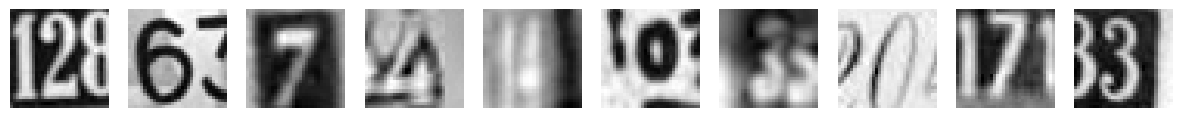

First 10 labels: [2 6 7 4 4 0 3 0 7 3]


In [6]:
# Show the first 10 training images with their labels underneath
plt.figure(figsize=(15, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.axis("off")
plt.show()

print(f"First 10 labels: {y_train[:10]}")

## **Data preparation**

- Print the shape and the array of pixels for the first image in the training dataset.
- Normalize the train and the test dataset by dividing by 255.
- Print the new shapes of the train and the test dataset.
- One-hot encode the target variable.

In [7]:
# Each image is a 32x32 grid of grayscale intensities (0-255)
print(f"Shape of the first image: {X_train[0].shape}")
print("Raw pixel array of the first image:\n", X_train[0])

Shape of the first image: (32, 32)
Raw pixel array of the first image:
 [[ 33.0704  30.2601  26.852  ...  71.4471  58.2204  42.9939]
 [ 25.2283  25.5533  29.9765 ... 113.0209 103.3639  84.2949]
 [ 26.2775  22.6137  40.4763 ... 113.3028 121.775  115.4228]
 ...
 [ 28.5502  36.212   45.0801 ...  24.1359  25.0927  26.0603]
 [ 38.4352  26.4733  23.2717 ...  28.1094  29.4683  30.0661]
 [ 50.2984  26.0773  24.0389 ...  49.6682  50.853   53.0377]]


### **Normalize the train and the test data**

In [8]:
# An ANN takes a flat vector, so each 32x32 image becomes a 1,024-element row
X_train_ann = X_train.reshape(X_train.shape[0], 1024)
X_test_ann = X_test.reshape(X_test.shape[0], 1024)

# Scale pixels from 0-255 to 0-1 so gradient descent converges faster and more stably
X_train_ann = X_train_ann / 255.0
X_test_ann = X_test_ann / 255.0

Print the shapes of Training and Test data

In [9]:
print(f"New flattened training data shape: {X_train_ann.shape}")
print(f"New flattened testing data shape: {X_test_ann.shape}")

New flattened training data shape: (42000, 1024)
New flattened testing data shape: (18000, 1024)


### **One-hot encode output**

In [10]:
# One-hot encode the labels: 5 -> [0,0,0,0,0,1,0,0,0,0], matching the 10 softmax outputs
y_train_encoded = to_categorical(y_train)
y_test_encoded = to_categorical(y_test)

print(f"One-hot encoded training labels shape: {y_train_encoded.shape}")

One-hot encoded training labels shape: (42000, 10)


**Observation:**

We successfully flattened the 32x32 image matrices into 1024-element 1D arrays. This is a mandatory step for Artificial Neural Networks, which cannot process 2D spatial grids.

The pixel values were normalized to fall between 0 and 1. This prevents large input values from causing exploding gradients and allows the network to learn more efficiently.

The target labels were one-hot encoded, transforming them from single integers into 10-element binary arrays. This perfectly aligns with the 10 output nodes (softmax) our model will use to predict the digits.


## **Model Building**

Now that we have done the data preprocessing, let's build an ANN model.

### Fix the seed for random number generators

In [11]:
def set_seeds(seed=42):
    """Fix Python, NumPy and TensorFlow seeds so runs are repeatable."""
    np.random.seed(seed)
    random.seed(seed)
    tf.random.set_seed(seed)

set_seeds()

### **Model Architecture**
- Write a function that returns a sequential model with the following architecture:
 - First hidden layer with **64 nodes and the relu activation** and the **input shape = (1024, )**
 - Second hidden layer with **32 nodes and the relu activation**
 - Output layer with **activation as 'softmax' and number of nodes equal to the number of classes, i.e., 10**
 - Compile the model with the **loss equal to categorical_crossentropy, optimizer equal to Adam(learning_rate = 0.001), and metric equal to 'accuracy'**. Do not fit the model here, just return the compiled model.
- Call the nn_model_1 function and store the model in a new variable.
- Print the summary of the model.
- Fit on the train data with a **validation split of 0.2, batch size = 128, verbose = 1, and epochs = 20**. Store the model building history to use later for visualization.

### **Build and train an ANN model as per the above mentioned architecture.**

In [12]:
def nn_model_1():
    """ANN Model 1: two small hidden layers (64 -> 32) and a 10-way softmax."""
    model = Sequential([
        Dense(64, activation="relu", input_shape=(1024,)),   # input: flattened 32x32 image
        Dense(32, activation="relu"),
        Dense(10, activation="softmax"),                     # one probability per digit
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

In [13]:
model_1 = nn_model_1()
model_1.summary()

# Train for 20 epochs, holding back 20% of the training data for validation
print("\nStarting Model 1 Training...")
history_1 = model_1.fit(
    X_train_ann, y_train_encoded,
    validation_split=0.2,
    batch_size=128,
    epochs=20,
    verbose=1,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 68,010 (265.66 KB)

Trainable params: 68,010 (265.66 KB)

Non-trainable params: 0 (0.00 B)


Starting Model 1 Training...
Epoch 1/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1073 - loss: 2.3092 - val_accuracy: 0.1632 - val_loss: 2.2677
Epoch 2/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1778 - loss: 2.2184 - val_accuracy: 0.2912 - val_loss: 2.0361
Epoch 3/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3392 - loss: 1.9184 - val_accuracy: 0.4385 - val_loss: 1.6545
Epoch 4/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4632 - loss: 1.6097 - val_accuracy: 0.5199 - val_loss: 1.4714
Epoch 5/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5245 - loss: 1.4635 - val_accuracy: 0.5400 - val_loss: 1.4094
Epoch 6/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5547 - loss: 1.3849 - val_accuracy: 0.5618 - val_loss: 1.3592
Epoch 7/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5754 - loss: 1.3310 - val_accuracy: 0.5861 - val_loss: 1.3045
Epoch 8/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5950 - l

### **Plot the Training and Validation Accuracies and write down your Observations.**

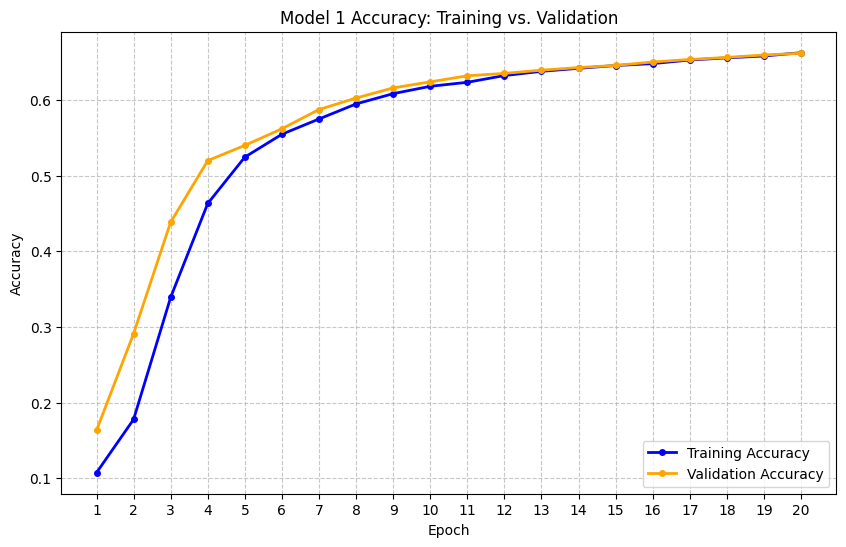

In [14]:
def plot_accuracy(history, title, xticks=None):
    """Plot training vs validation accuracy from a Keras History object."""
    plt.figure(figsize=(10, 6))
    plt.plot(history.history["accuracy"], label="Training Accuracy", color="blue", linewidth=2)
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy", color="orange", linewidth=2)
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    if xticks is not None:
        plt.xticks(xticks)
    plt.legend(loc="lower right")
    plt.grid(True, linestyle="--", alpha=0.7)
    plt.show()

plot_accuracy(history_1, "Model 1 Accuracy: Training vs. Validation")

**Observations — ANN Model 1:**

- **Rapid initial learning:** accuracy climbs steeply over the first 5 epochs, from about 0.10 to over 0.50.
- **No overfitting:** validation accuracy tracks training accuracy closely throughout, so the model generalises what it learns.
- **Plateau:** improvement slows after epoch 10 and the curves flatten.
- **Limited capacity:** both curves are still creeping up at epoch 20, but the model is close to the ceiling for this small architecture, finishing at roughly **66%** validation accuracy.

Let's build one more model with higher complexity and see if we can improve the performance of the model.

First, we need to clear the previous model's history from the Keras backend. Also, let's fix the seed again after clearing the backend.

### **Second Model Architecture**
- Write a function that returns a sequential model with the following architecture:
 - First hidden layer with **256 nodes and the relu activation** and the **input shape = (1024, )**
 - Second hidden layer with **128 nodes and the relu activation**
 - Add the **Dropout layer with the rate equal to 0.2**
 - Third hidden layer with **64 nodes and the relu activation**
 - Fourth hidden layer with **64 nodes and the relu activation**
 - Fifth hidden layer with **32 nodes and the relu activation**
 - Add the **BatchNormalization layer**
 - Output layer with **activation as 'softmax' and number of nodes equal to the number of classes, i.e., 10**
 -Compile the model with the **loss equal to categorical_crossentropy, optimizer equal to Adam(learning_rate = 0.0005), and metric equal to 'accuracy'**. Do not fit the model here, just return the compiled model.
- Call the nn_model_2 function and store the model in a new variable.
- Print the summary of the model.
- Fit on the train data with a **validation split of 0.2, batch size = 128, verbose = 1, and epochs = 30**. Store the model building history to use later for visualization.

### **Build and train the new ANN model as per the above mentioned architecture**

In [15]:
# Reset Keras state and seeds so Model 2 starts from a clean slate
K.clear_session()
set_seeds()

def nn_model_2():
    """ANN Model 2: deeper and wider (256-128-64-64-32) with Dropout and BatchNorm."""
    model = Sequential([
        Dense(256, activation="relu", input_shape=(1024,)),
        Dense(128, activation="relu"),
        Dropout(0.2),                        # randomly drop 20% of units to reduce overfitting
        Dense(64, activation="relu"),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        BatchNormalization(),                # re-centre/re-scale activations before the output
        Dense(10, activation="softmax"),
    ])
    model.compile(optimizer=Adam(learning_rate=0.0005),   # smaller step size for the deeper net
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model_2 = nn_model_2()
model_2.summary()

print("\nStarting Model 2 Training...")
history_2 = model_2.fit(
    X_train_ann, y_train_encoded,
    validation_split=0.2,
    batch_size=128,
    verbose=1,
    epochs=30,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 310,250 (1.18 MB)

Trainable params: 310,186 (1.18 MB)

Non-trainable params: 64 (256.00 B)


Starting Model 2 Training...
Epoch 1/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.0983 - loss: 2.4457 - val_accuracy: 0.1279 - val_loss: 2.3020
Epoch 2/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1364 - loss: 2.2729 - val_accuracy: 0.2926 - val_loss: 2.0787
Epoch 3/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3587 - loss: 1.8095 - val_accuracy: 0.5064 - val_loss: 1.4461
Epoch 4/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5101 - loss: 1.4419 - val_accuracy: 0.6002 - val_loss: 1.2419
Epoch 5/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5695 - loss: 1.3004 - val_accuracy: 0.6015 - val_loss: 1.2022
Epoch 6/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6087 - loss: 1.1993 - val_accuracy: 0.6220 - val_loss: 1.1669
Epoch 7/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6319 - loss: 1.1292 - val_accuracy: 0.6571 - val_loss: 1.0722
Epoch 8/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6543 - 

### **Plot the Training and Validation Accuracies and write down your Observations.**

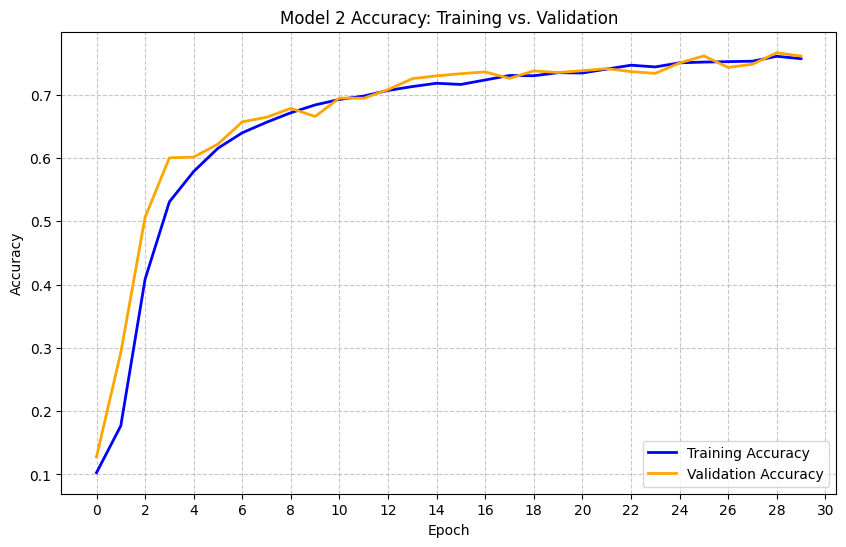

In [16]:
plot_accuracy(history_2, "Model 2 Accuracy: Training vs. Validation", xticks=range(0, 31, 2))

**Observations — ANN Model 2:**

- **Clear improvement:** validation accuracy reaches about **76%** (peaking at 76.6%), well above Model 1's ~66%. The extra depth lets the network learn more complex patterns.
- **Good generalisation:** training and validation curves stay close for all 30 epochs, so the model is not memorising the training data.
- **Effect of Dropout:** validation accuracy sometimes sits slightly above training accuracy. That is expected with Dropout, because units are switched off during training but all are active during validation.
- **Convergence:** learning is steep for the first 10 epochs and levels off from around epoch 25, so 30 epochs was a sensible budget.

## **Predictions on the test data**

- Make predictions on the test set using the second model.
- Print the obtained results using the classification report and the confusion matrix.
- Final observations on the obtained results.

In [17]:
# Predicted class probabilities for the 18,000 test images
print("Generating predictions on the test data...")
y_pred_probs = model_2.predict(X_test_ann)

Generating predictions on the test data...
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


**Note:** Earlier, we noticed that each entry of the target variable is a one-hot encoded vector but to print the classification report and confusion matrix, we must convert each entry of y_test to a single label.

In [18]:
# Convert probabilities and one-hot labels back to single digit labels (0-9)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_test_classes = np.argmax(y_test_encoded, axis=1)

### **Print the classification report and the confusion matrix for the test predictions. Write your observations on the final results.**


CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.79      0.80      0.79      1814
           1       0.76      0.81      0.79      1828
           2       0.80      0.78      0.79      1803
           3       0.69      0.75      0.72      1719
           4       0.84      0.77      0.81      1812
           5       0.70      0.74      0.72      1768
           6       0.78      0.73      0.76      1832
           7       0.80      0.80      0.80      1808
           8       0.71      0.74      0.72      1812
           9       0.79      0.71      0.75      1804

    accuracy                           0.76     18000
   macro avg       0.77      0.76      0.76     18000
weighted avg       0.77      0.76      0.76     18000



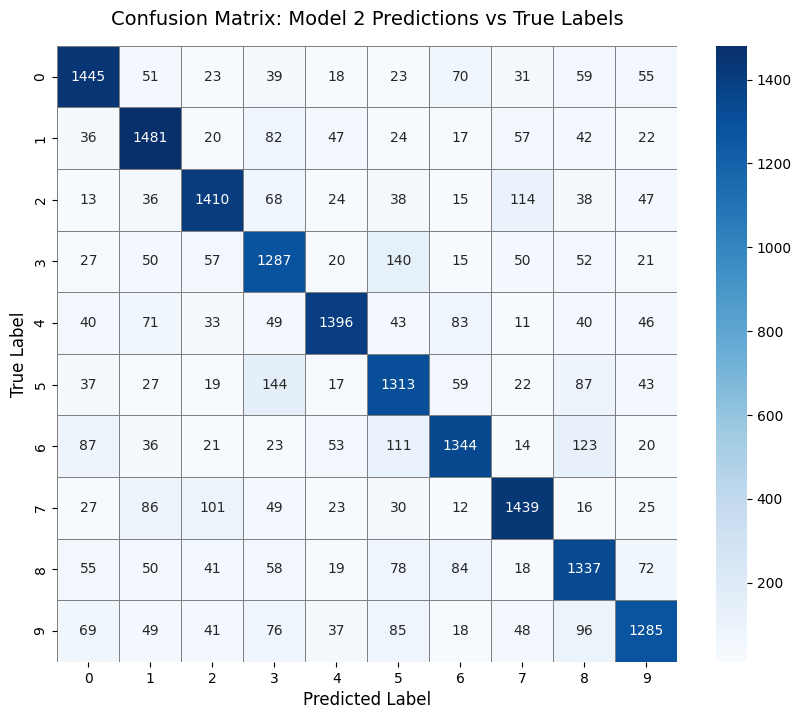

In [19]:
def report_and_confusion(y_true, y_pred, title, header="CLASSIFICATION REPORT"):
    """Print the classification report and plot the confusion matrix."""
    print("\n" + "=" * 50)
    print(header)
    print("=" * 50)
    print(classification_report(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=range(10), yticklabels=range(10),
                linewidths=0.5, linecolor="gray")
    plt.title(title, fontsize=14, pad=15)
    plt.xlabel("Predicted Label", fontsize=12)
    plt.ylabel("True Label", fontsize=12)
    plt.show()

report_and_confusion(y_test_classes, y_pred_classes, "Confusion Matrix: Model 2 Predictions vs True Labels")

**Final Observations — ANN Model 2 on the test set:**

- **Consistent generalisation:** **76%** accuracy on 18,000 unseen test images, in line with the validation accuracy during training, so the model is not overfitting.
- **Balanced performance:** macro-averaged precision, recall and F1 are all 0.76–0.77, so no single digit is failing badly.
- **Strongest digits:** 4 (F1 0.81) and 7 (F1 0.80), followed by 0, 1 and 2 (F1 0.79).
- **Weakest digits:** 3, 5 and 8 (F1 0.72). Digit 3 has the lowest precision (0.69), meaning other digits are often mistaken for a 3. Digit 9 has the lowest recall (0.71), so many real 9s are missed. These digits share curved strokes, and once an image is flattened into a 1-D vector the network loses the spatial layout that separates them.
- **Conclusion:** 76% is a reasonable baseline for a fully connected network on noisy natural images. Because flattening discards spatial structure (edges, curves, relative position), the next step is a CNN, which works directly on the 2-D image.

## **Using Convolutional Neural Networks**

### **Load the dataset again and split the data into the train and the test dataset.**

In [20]:
# Reload the raw arrays so the CNN pipeline starts from the original 32x32 images
X_train, y_train, X_test, y_test = load_svhn(DATA_PATH)
print("Dataset loaded successfully!")

Dataset loaded successfully!


Check the number of images in the training and the testing dataset.

In [21]:
print(f"Number of training images: {X_train.shape[0]}")
print(f"Number of testing images: {X_test.shape[0]}")

Number of training images: 42000
Number of testing images: 18000


**Observation:** Same 42,000 / 18,000 split as before.

## **Data preparation**

- Print the shape and the array of pixels for the first image in the training dataset.
- Reshape the train and the test dataset because we always have to give a 4D array as input to CNNs.
- Normalize the train and the test dataset by dividing by 255.
- Print the new shapes of the train and the test dataset.
- One-hot encode the target variable.

In [22]:
print(f"Shape of the first image: {X_train[0].shape}")
print("Raw pixel array of the first image:\n", X_train[0])

Shape of the first image: (32, 32)
Raw pixel array of the first image:
 [[ 33.0704  30.2601  26.852  ...  71.4471  58.2204  42.9939]
 [ 25.2283  25.5533  29.9765 ... 113.0209 103.3639  84.2949]
 [ 26.2775  22.6137  40.4763 ... 113.3028 121.775  115.4228]
 ...
 [ 28.5502  36.212   45.0801 ...  24.1359  25.0927  26.0603]
 [ 38.4352  26.4733  23.2717 ...  28.1094  29.4683  30.0661]
 [ 50.2984  26.0773  24.0389 ...  49.6682  50.853   53.0377]]


Reshape the dataset to be able to pass them to CNNs. Remember that we always have to give a 4D array as input to CNNs

In [23]:
# CNNs expect 4-D input: (samples, height, width, channels). Grayscale -> 1 channel.
X_train_cnn = X_train.reshape(X_train.shape[0], 32, 32, 1)
X_test_cnn = X_test.reshape(X_test.shape[0], 32, 32, 1)

Normalize inputs from 0-255 to 0-1

In [24]:
# Scale pixels to 0-1
X_train_cnn = X_train_cnn / 255.0
X_test_cnn = X_test_cnn / 255.0

Print New shape of Training and Test

In [25]:
print(f"New CNN training data shape: {X_train_cnn.shape}")
print(f"New CNN testing data shape: {X_test_cnn.shape}")

New CNN training data shape: (42000, 32, 32, 1)
New CNN testing data shape: (18000, 32, 32, 1)


### **One-hot encode the labels in the target variable y_train and y_test.**

In [26]:
y_train_encoded = to_categorical(y_train)
y_test_encoded = to_categorical(y_test)

print(f"One-hot encoded training labels shape: {y_train_encoded.shape}")

One-hot encoded training labels shape: (42000, 10)


**Observation:** Unlike the ANN, the images keep their 32×32 spatial layout (with one channel), so convolutional filters can learn local patterns such as edges and curves. Pixels are scaled to 0–1 and labels are one-hot encoded as before.

## **Model Building**

Now that we have done data preprocessing, let's build a CNN model.
Fix the seed for random number generators

In [27]:
# Fresh session and seeds before building the first CNN
K.clear_session()
set_seeds()

### **Model Architecture**
- **Write a function** that returns a sequential model with the following architecture:
 - First Convolutional layer with **16 filters and the kernel size of 3x3**. Use the **'same' padding** and provide the **input shape = (32, 32, 1)**
 - Add a **LeakyRelu layer** with the **slope equal to 0.1**
 - Second Convolutional layer with **32 filters and the kernel size of 3x3 with 'same' padding**
 - Another **LeakyRelu** with the **slope equal to 0.1**
 - A **max-pooling layer** with a **pool size of 2x2**
 - **Flatten** the output from the previous layer
 - Add a **dense layer with 32 nodes**
 - Add a **LeakyRelu layer with the slope equal to 0.1**
 - Add the final **output layer with nodes equal to the number of classes, i.e., 10** and **'softmax' as the activation function**
 - Compile the model with the **loss equal to categorical_crossentropy, optimizer equal to Adam(learning_rate = 0.001), and metric equal to 'accuracy'**. Do not fit the model here, just return the compiled model.
- Call the function cnn_model_1 and store the output in a new variable.
- Print the summary of the model.
- Fit the model on the training data with a **validation split of 0.2, batch size = 32, verbose = 1, and epochs = 20**. Store the model building history to use later for visualization.

### **Build and train a CNN model as per the above mentioned architecture.**

In [28]:
def cnn_model_1():
    """CNN Model 1: two 3x3 conv layers, one max-pool, a 32-unit dense layer."""
    model = Sequential()

    # Conv block: 16 then 32 filters, 'same' padding keeps the 32x32 size
    model.add(Conv2D(filters=16, kernel_size=(3, 3), padding="same", input_shape=(32, 32, 1)))
    model.add(LeakyReLU(alpha=0.1))          # small slope for negative inputs avoids "dead" units
    model.add(Conv2D(filters=32, kernel_size=(3, 3), padding="same"))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling2D(pool_size=(2, 2)))  # 32x32 -> 16x16

    # Classifier: 16*16*32 = 8,192 features -> 32 units -> 10 classes
    model.add(Flatten())
    model.add(Dense(32))
    model.add(LeakyReLU(alpha=0.1))
    model.add(Dense(10, activation="softmax"))

    model.compile(loss="categorical_crossentropy",
                  optimizer=Adam(learning_rate=0.001),
                  metrics=["accuracy"])
    return model

cnn_1 = cnn_model_1()
cnn_1.summary()

print("\nStarting CNN Model 1 Training...")
history_cnn_1 = cnn_1.fit(
    X_train_cnn, y_train_encoded,
    validation_split=0.2,
    batch_size=32,
    epochs=20,
    verbose=1,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       262,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 267,306 (1.02 MB)

Trainable params: 267,306 (1.02 MB)

Non-trainable params: 0 (0.00 B)


Starting CNN Model 1 Training...
Epoch 1/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.4166 - loss: 1.6466 - val_accuracy: 0.8161 - val_loss: 0.6398
Epoch 2/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8310 - loss: 0.5734 - val_accuracy: 0.8346 - val_loss: 0.5641
Epoch 3/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8626 - loss: 0.4682 - val_accuracy: 0.8592 - val_loss: 0.5076
Epoch 4/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8808 - loss: 0.4001 - val_accuracy: 0.8586 - val_loss: 0.5058
Epoch 5/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8977 - loss: 0.3509 - val_accuracy: 0.8595 - val_loss: 0.5120
Epoch 6/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9105 - loss: 0.3114 - val_accuracy: 0.8661 - val_loss: 0.5104
Epoch 7/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9197 - loss: 0.2779 - val_accuracy: 0.8637 - val_loss: 0.5212
Epoch 8/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - 

### **Plot the Training and Validation Accuracies and Write your observations.**

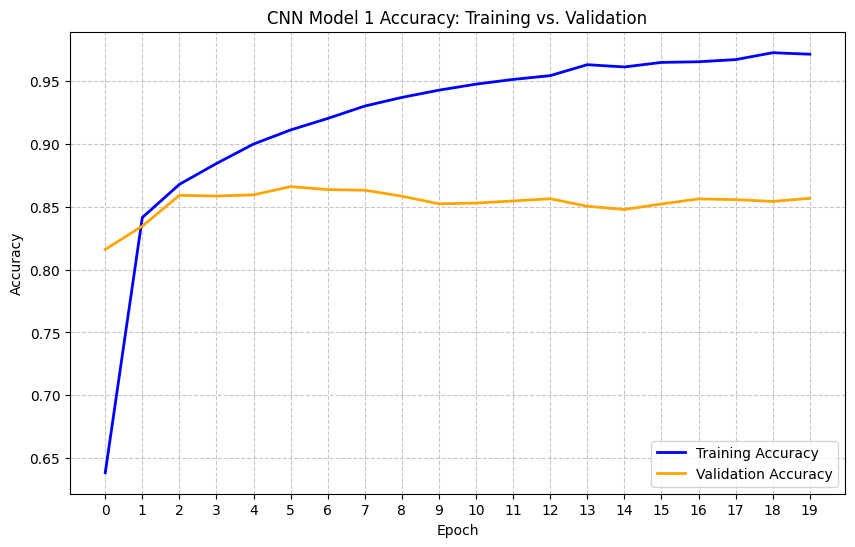

In [29]:
plot_accuracy(history_cnn_1, "CNN Model 1 Accuracy: Training vs. Validation", xticks=range(0, 20))

**Observations — CNN Model 1:**

- **Big jump over the ANNs:** validation accuracy reaches about **86%** within 3–5 epochs, already ~10 points above the best fully connected network. Convolutions clearly help.
- **Clear overfitting:** training accuracy keeps rising to about **97%**, while validation accuracy plateaus around 85–86% and drifts slightly down.
- **Validation loss gets worse:** validation loss bottoms out at about 0.51 around epoch 4 and then climbs to about 0.97 by epoch 20. The model becomes more confident on training images while getting worse on unseen ones.
- **Why:** there is no regularisation (no Dropout or BatchNorm), and the network flattens 8,192 features straight into a dense layer, so it can easily memorise the training set.
- **Conclusion:** the architecture can learn the task but needs regularisation and a deeper feature extractor. The next model adds BatchNorm, Dropout, more conv layers and early stopping.

Let's build another model and see if we can get a better model with generalized performance.

First, we need to clear the previous model's history from the Keras backend. Also, let's fix the seed again after clearing the backend.

In [30]:
# Fresh session and seeds before building the second CNN
K.clear_session()
set_seeds()

### **Second Model Architecture**

- Write a function that returns a sequential model with the following architecture:
 - First Convolutional layer with **16 filters and the kernel size of 3x3**. Use the **'same' padding** and provide the **input shape = (32, 32, 1)**
 - Add a **LeakyRelu layer** with the **slope equal to 0.1**
 - Second Convolutional layer with **32 filters and the kernel size of 3x3 with 'same' padding**
 - Add **LeakyRelu** with the **slope equal to 0.1**
 - Add a **max-pooling layer** with a **pool size of 2x2**
 - Add a **BatchNormalization layer**
 - Third Convolutional layer with **32 filters and the kernel size of 3x3 with 'same' padding**
 - Add a **LeakyRelu layer with the slope equal to 0.1**
 - Fourth Convolutional layer **64 filters and the kernel size of 3x3 with 'same' padding**
 - Add a **LeakyRelu layer with the slope equal to 0.1**
 - Add a **max-pooling layer** with a **pool size of 2x2**
 - Add a **BatchNormalization layer**
 - **Flatten** the output from the previous layer
 - Add a **dense layer with 32 nodes**
 - Add a **LeakyRelu layer with the slope equal to 0.1**
 - Add a **dropout layer with the rate equal to 0.5**
 - Add the final **output layer with nodes equal to the number of classes, i.e., 10** and **'softmax' as the activation function**
 - Compile the model with the **categorical_crossentropy loss, adam optimizers (learning_rate = 0.001), and metric equal to 'accuracy'**. Do not fit the model here, just return the compiled model.
- Call the function cnn_model_2 and store the model in a new variable.
- Print the summary of the model.
- Fit the model on the train data with a **validation split of 0.2, batch size = 128, verbose = 1, and epochs = 30**. Store the model building history to use later for visualization.

### **Build and train the second CNN model as per the above mentioned architecture.**

In [31]:
def cnn_model_2():
    """CNN Model 2: four conv layers in two blocks, BatchNorm after each block, Dropout in the head."""
    model = Sequential()

    # Block 1: 16 -> 32 filters, then pool (32x32 -> 16x16) and BatchNorm
    model.add(Conv2D(filters=16, kernel_size=(3, 3), padding="same", input_shape=(32, 32, 1)))
    model.add(LeakyReLU(alpha=0.1))
    model.add(Conv2D(filters=32, kernel_size=(3, 3), padding="same"))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(BatchNormalization())

    # Block 2: 32 -> 64 filters, then pool (16x16 -> 8x8) and BatchNorm
    model.add(Conv2D(filters=32, kernel_size=(3, 3), padding="same"))
    model.add(LeakyReLU(alpha=0.1))
    model.add(Conv2D(filters=64, kernel_size=(3, 3), padding="same"))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(BatchNormalization())

    # Classifier head with heavy Dropout (50%) to curb overfitting
    model.add(Flatten())
    model.add(Dense(32))
    model.add(LeakyReLU(alpha=0.1))
    model.add(Dropout(0.5))
    model.add(Dense(10, activation="softmax"))

    model.compile(loss="categorical_crossentropy",
                  optimizer=Adam(learning_rate=0.001),
                  metrics=["accuracy"])
    return model

cnn_2 = cnn_model_2()
cnn_2.summary()

# Early stopping (added beyond the brief): stop when validation loss hasn't improved
# for 5 epochs and roll back to the best weights seen.
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

print("\nStarting CNN Model 2 Training with Callbacks...")
history_cnn_2 = cnn_2.fit(
    X_train_cnn, y_train_encoded,
    validation_split=0.2,
    batch_size=128,
    epochs=30,
    callbacks=[early_stop],
    verbose=1,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       131,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 164,362 (642.04 KB)

Trainable params: 164,170 (641.29 KB)

Non-trainable params: 192 (768.00 B)


Starting CNN Model 2 Training with Callbacks...
Epoch 1/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 13s 26ms/step - accuracy: 0.3279 - loss: 1.9327 - val_accuracy: 0.1756 - val_loss: 2.1724
Epoch 2/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7746 - loss: 0.7267 - val_accuracy: 0.8404 - val_loss: 0.5513
Epoch 3/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8223 - loss: 0.5782 - val_accuracy: 0.8695 - val_loss: 0.4446
Epoch 4/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8453 - loss: 0.5011 - val_accuracy: 0.8798 - val_loss: 0.4210
Epoch 5/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8610 - loss: 0.4542 - val_accuracy: 0.8810 - val_loss: 0.4105
Epoch 6/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8748 - loss: 0.4117 - val_accuracy: 0.8833 - val_loss: 0.3992
Epoch 7/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8779 - loss: 0.3930 - val_accuracy: 0.9042 - val_loss: 0.3541
Epoch 8/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step 

### **Plot the Training and Validation accuracies and write your observations.**

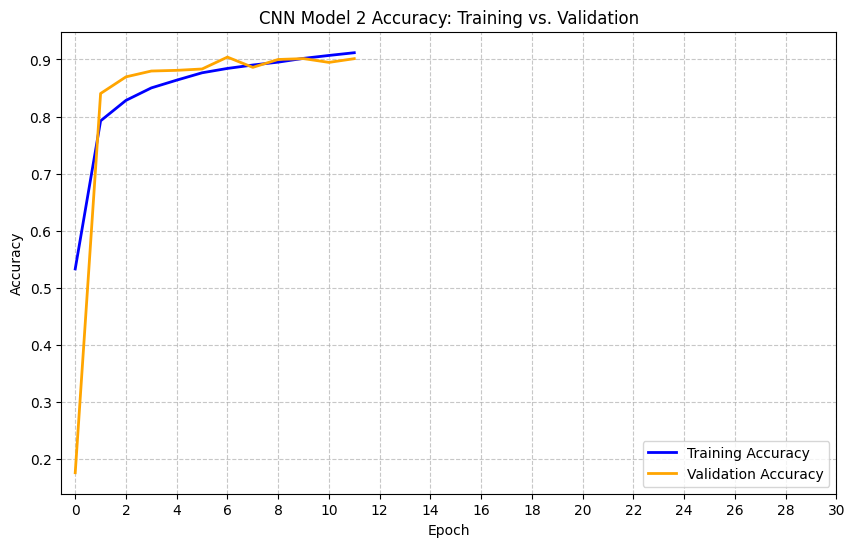

In [32]:
plot_accuracy(history_cnn_2, "CNN Model 2 Accuracy: Training vs. Validation", xticks=range(0, 31, 2))

**Observations — CNN Model 2:**

- **Early stopping worked as intended:** validation loss was lowest at **epoch 7 (0.354)**. After 5 more epochs without improvement, training stopped at **epoch 12** and the epoch-7 weights were restored.
- **Overfitting fixed:** unlike CNN Model 1, training and validation accuracy stay together (both ~90% by the end). BatchNorm stabilises the activations and Dropout stops the dense head from memorising.
- **Best validation accuracy so far:** about **90%**, compared with ~86% for CNN Model 1 and ~76% for the best ANN.
- **CNN vs ANN:** convolutional filters learn 2-D spatial features (edges, strokes, curves) that a fully connected network loses when it flattens the image, and that drives the ~14-point gap.

## **Predictions on the test data**

- Make predictions on the test set using the second model.
- Print the obtained results using the classification report and the confusion matrix.
- Final observations on the obtained results.

### **Make predictions on the test data using the second model.**

Generating predictions on the CNN test data...
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

CLASSIFICATION REPORT: CNN MODEL 2
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      1814
           1       0.91      0.89      0.90      1828
           2       0.91      0.92      0.92      1803
           3       0.87      0.88      0.87      1719
           4       0.92      0.92      0.92      1812
           5       0.87      0.90      0.88      1768
           6       0.87      0.89      0.88      1832
           7       0.93      0.91      0.92      1808
           8       0.91      0.86      0.88      1812
           9       0.91      0.88      0.89      1804

    accuracy                           0.90     18000
   macro avg       0.90      0.90      0.90     18000
weighted avg       0.90      0.90      0.90     18000



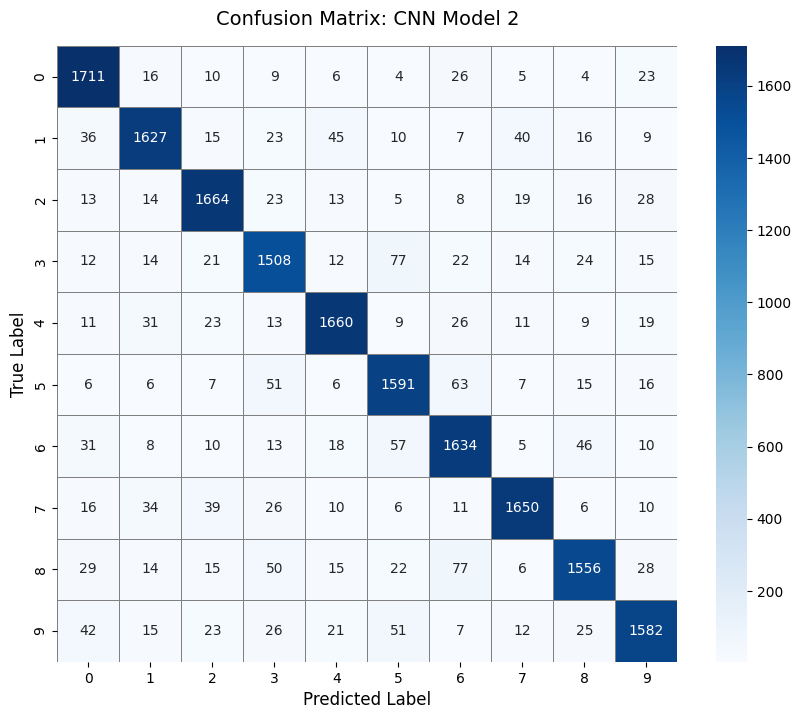

In [33]:
print("Generating predictions on the CNN test data...")
y_pred_probs_cnn = cnn_2.predict(X_test_cnn)

# Back to single digit labels for the report
y_pred_classes_cnn = np.argmax(y_pred_probs_cnn, axis=1)
y_test_classes_cnn = np.argmax(y_test_encoded, axis=1)

report_and_confusion(y_test_classes_cnn, y_pred_classes_cnn,
                     "Confusion Matrix: CNN Model 2", header="CLASSIFICATION REPORT: CNN MODEL 2")

**Final Observations:**

- **Test performance:** CNN Model 2 reaches **90% accuracy** on the 18,000 test images, with macro-averaged precision, recall and F1 all at 0.90. That matches its validation accuracy, so it generalises well.
- **Per digit:** F1-scores range from 0.87 (digit 3) to 0.92 (digits 0, 2, 4 and 7). Even the weakest digit is now well above the ANN's best classes. Digit 8 has the lowest recall (0.86).

**Model comparison**

| Model | Validation accuracy | Test accuracy | Notes |
| --- | ---: | ---: | --- |
| ANN Model 1 | ~66% | — | underfits; too small |
| ANN Model 2 | ~76% | 76% | good generalisation, limited by flattening |
| CNN Model 1 | ~86% | — | strong features but overfits (val loss rises from epoch 4) |
| **CNN Model 2** | **~90%** | **90%** | BatchNorm + Dropout + early stopping |

**Final model selection:** **CNN Model 2** is the recommended model. It is the most accurate, its per-digit performance is the most even, and it has fewer parameters than either CNN Model 1 or ANN Model 2 (164K vs 267K and 310K). Next steps could include data augmentation (small shifts and rotations), a deeper third conv block, and learning-rate scheduling.